# 01 · Data exploration

The dataset has 68 facial landmarks per face, on frames taken from the [YouTube Faces Dataset](https://www.cs.tau.ac.il/~wolf/ytfaces/) (Wolf et al., 2011). This notebook looks at how the data is organized, checks two things that turn out to matter (how the train/test split was made and how the image files are stored) and sets up the preprocessing used in training.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable

import config

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from torchvision import transforms

from data_load import (CenterCrop, FacialKeypointsDataset, Normalize, RandomCrop, Rescale,
                       ToTensor, download_data, identity_of, read_rgb)

download_data()  # ~340 MB into data/ (or $FKD_DATA_ROOT); skipped if already there

PosixPath('/Users/ignacioquintero/Projects/udacity-computer-vision/facial_keypoints_detection/data')

## The dataset at a glance

In [2]:
train = pd.read_csv(config.TRAIN_CSV)
test = pd.read_csv(config.TEST_CSV)
print(f"Columns: file name + {train.shape[1] - 1} coordinates ({(train.shape[1] - 1) // 2} keypoints)")

def clip_of(name):
    return name[:-5]  # 'Luis_Fonsi_21.jpg' -> 'Luis_Fonsi_2' (person + clip index)

for split, df, folder in [("train", train, config.TRAIN_DIR), ("test", test, config.TEST_DIR)]:
    files = len(list(folder.iterdir()))
    print(f"{split:5s}: {len(df):4d} annotated images ({files} files in the folder), "
          f"{df.iloc[:, 0].map(identity_of).nunique()} people, {df.iloc[:, 0].map(clip_of).nunique()} clips")

Columns: file name + 136 coordinates (68 keypoints)
train: 3462 annotated images (3462 files in the folder), 347 people, 1154 clips
test :  770 annotated images (2308 files in the folder), 347 people, 770 clips


Two details are easy to miss:

- `test/` contains 2,308 files, but only **770** of them have keypoints in `test_frames_keypoints.csv`. The other 1,538 have no labels and are ignored.
- File names follow `<person>_<clip><frame>.jpg`. For example, `Luis_Fonsi_21.jpg` is frame 1 of clip 2. Each person has about 10 training frames, taken from 3–4 short clips.

## How train and test were split

In [3]:
train_people, test_people = set(train.iloc[:, 0].map(identity_of)), set(test.iloc[:, 0].map(identity_of))
train_clips, test_clips = set(train.iloc[:, 0].map(clip_of)), set(test.iloc[:, 0].map(clip_of))
print(f"People in both splits: {len(train_people & test_people)} of {len(test_people)}")
print(f"Test clips that also appear in train: {len(test_clips & train_clips)} of {len(test_clips)}")
print(f"Test file names that also exist in train: {test.iloc[:, 0].isin(train.iloc[:, 0]).sum()} of {len(test)}")

People in both splits: 347 of 347
Test clips that also appear in train: 770 of 770
Test file names that also exist in train: 770 of 770


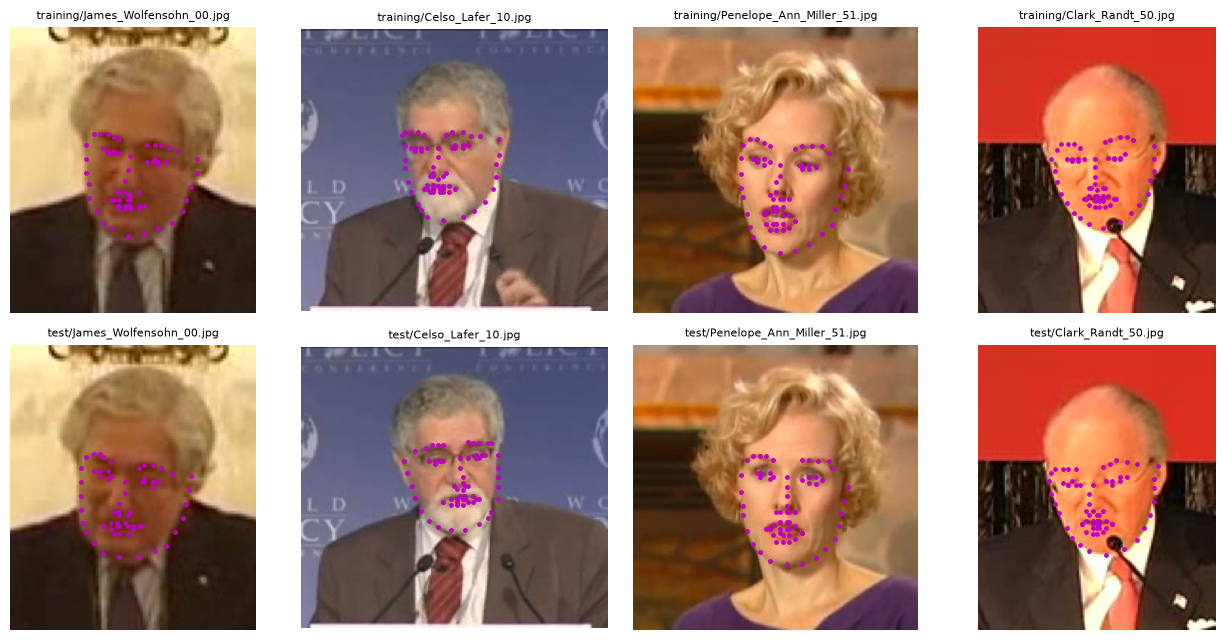

In [4]:
# Same file name in both folders: same clip, a different frame.
train_idx, test_idx = train.set_index(train.columns[0]), test.set_index(test.columns[0])
names = test.iloc[[0, 100, 300, 500], 0]
fig, axes = plt.subplots(2, len(names), figsize=(13, 6.5))
for j, name in enumerate(names):
    for i, (folder, idx) in enumerate([(config.TRAIN_DIR, train_idx), (config.TEST_DIR, test_idx)]):
        pts = idx.loc[name].to_numpy(float).reshape(-1, 2)
        axes[i, j].imshow(read_rgb(folder / name))
        axes[i, j].scatter(pts[:, 0], pts[:, 1], s=6, c="m")
        axes[i, j].set_title(f"{folder.name}/{name}", fontsize=8)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

**The test set is not held out by person, or even by clip.** All 770 test images come from clips that are also in the training set. They are neighboring frames of the same video, with the same framing and almost the same pose. Two of them are byte-identical to a training image.

What this means for the rest of the project:

- The official test set measures how well the model generalizes **to new frames of videos it has already seen**. That is an easier task than generalizing to new people, so the error on it is optimistic.
- The validation split for training (notebook 02) is therefore made **by person**: nobody in validation appears in the training subset. Validation error estimates performance on unseen faces more realistically, and model selection uses only that split.

## Image files

In [5]:
name = train.iloc[0, 0]
with Image.open(config.TRAIN_DIR / name) as im:
    print(f"{name}: format={im.format}, mode={im.mode}, size={im.size}")

as_mpimg = mpimg.imread(config.TRAIN_DIR / name)
print(f"matplotlib.image.imread -> dtype={as_mpimg.dtype}, range=[{as_mpimg.min():.2f}, {as_mpimg.max():.2f}]")
as_uint8 = read_rgb(config.TRAIN_DIR / name)
print(f"data_load.read_rgb      -> dtype={as_uint8.dtype}, range=[{as_uint8.min()}, {as_uint8.max()}]")

Luis_Fonsi_21.jpg: format=PNG, mode=RGBA, size=(176, 192)
matplotlib.image.imread -> dtype=float32, range=[0.00, 1.00]
data_load.read_rgb      -> dtype=uint8, range=[0, 248]


Every image is an **RGBA PNG saved with a `.jpg` extension**. That matters because of how they get read:

- `matplotlib.image.imread`, which the starter code used, returns PNGs as `float32` already scaled to [0, 1].
- The `Normalize` transform then divides by 255 again.

As a result, the model submitted to the Nanodegree (v0) was trained on images in **[0, 0.004]**: nearly black, with almost no contrast for the convolutions to pick up. Notebook 03 shows what that did to the model. `data_load.read_rgb` now reads every file as `uint8` RGB, so `Normalize` produces the intended [0, 1] range.

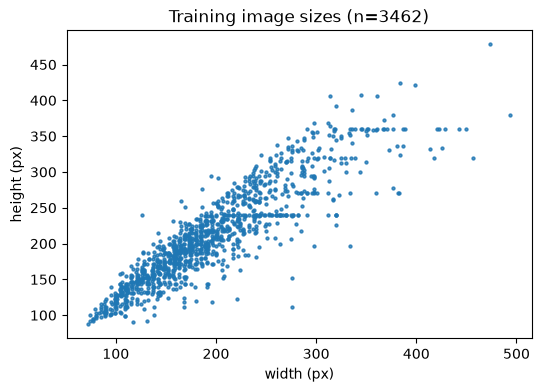

width 72–494 px, height 87–478 px, median [184 201]


In [6]:
sizes = np.array([Image.open(config.TRAIN_DIR / n).size for n in train.iloc[:, 0]])
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(sizes[:, 0], sizes[:, 1], s=4, alpha=0.4)
ax.set_xlabel("width (px)"); ax.set_ylabel("height (px)")
ax.set_title(f"Training image sizes (n={len(sizes)})")
plt.show()
print(f"width {sizes[:, 0].min()}–{sizes[:, 0].max()} px, height {sizes[:, 1].min()}–{sizes[:, 1].max()} px, "
      f"median {np.median(sizes, axis=0).astype(int)}")

Images vary in size, but each is a loose crop around one face: forehead, ears and chin are all in view. The network will always see a fixed 224×224 crop.

## Samples

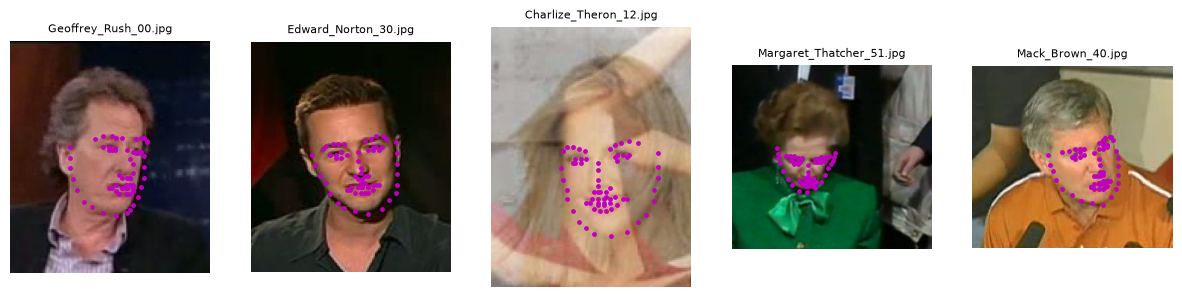

In [7]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
for ax, i in zip(axes, rng.choice(len(train), 5, replace=False)):
    name = train.iloc[i, 0]
    pts = train.iloc[i, 1:].to_numpy(float).reshape(-1, 2)
    ax.imshow(read_rgb(config.TRAIN_DIR / name))
    ax.scatter(pts[:, 0], pts[:, 1], s=6, c="m")
    ax.set_title(name, fontsize=8)
    ax.axis("off")
plt.show()

## Landmark layout

The 68 points follow the iBUG / Multi-PIE convention. The figure shows the mean shape of the training set in the network's 224×224 input frame, with each point labelled by its 0-based index. Notebook 05 uses this indexing to place a filter: 17 and 26 are the outer eyebrow corners, 27–35 the nose, and 36 and 45 the outer eye corners (also used to normalize errors).

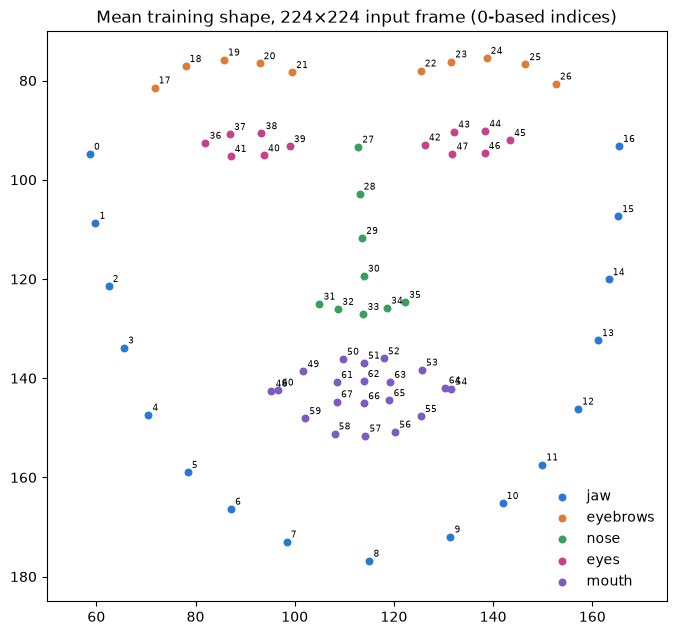

In [8]:
eval_tf = transforms.Compose([Rescale(config.RESCALE_SIZE), CenterCrop(config.IMAGE_SIZE)])
mean_shape = np.mean([eval_tf(FacialKeypointsDataset(train, config.TRAIN_DIR)[i])["keypoints"]
                      for i in range(len(train))], axis=0)

colors = {"jaw": "#2a78d6", "eyebrows": "#e07b39", "nose": "#3a9e5c", "eyes": "#c9408a", "mouth": "#7b5cc4"}
fig, ax = plt.subplots(figsize=(8, 7.5))
for region, idx in config.REGIONS.items():
    p = mean_shape[list(idx)]
    ax.scatter(p[:, 0], p[:, 1], s=22, color=colors[region], label=region)
    for k in idx:
        ax.annotate(str(k), mean_shape[k], xytext=(3, 3), textcoords="offset points", fontsize=6.5)
ax.set_xlim(50, 175); ax.set_ylim(185, 70); ax.set_aspect("equal")  # zoom on the face
ax.legend(frameon=False, loc="lower right")
ax.set_title("Mean training shape, 224×224 input frame (0-based indices)")
config.ASSETS_DIR.mkdir(exist_ok=True)
fig.savefig(config.ASSETS_DIR / "landmark_index.png", dpi=130, bbox_inches="tight")
plt.show()

## Preprocessing

`data_load.py` defines four transforms that are composed in order. Order matters: an image has to be rescaled before it can be cropped below its original size.

| Transform | Train | Validation / test |
|---|---|---|
| `Rescale(250)` | shorter side → 250 px, aspect kept | same |
| crop to 224×224 | `RandomCrop` (small translation augmentation) | `CenterCrop` (deterministic) |
| `Normalize` | grayscale in [0, 1]; keypoints → `(pts − 100) / 50` | same |
| `ToTensor` | `H×W` → `1×H×W` float tensor | same |

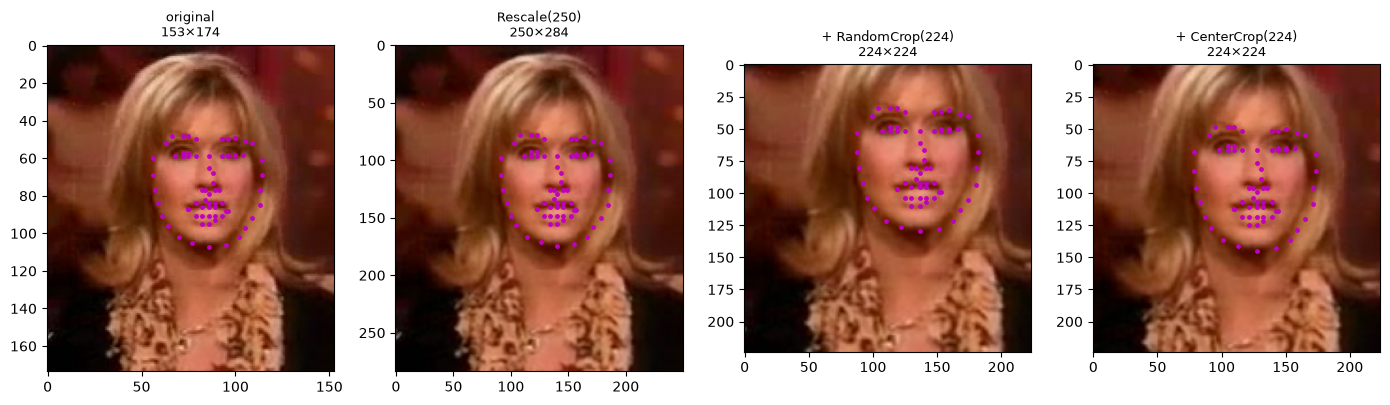

In [9]:
dataset = FacialKeypointsDataset(train, config.TRAIN_DIR)
sample = dataset[500]
steps = [("original", lambda s: s), ("Rescale(250)", Rescale(250)),
         ("+ RandomCrop(224)", transforms.Compose([Rescale(250), RandomCrop(224)])),
         ("+ CenterCrop(224)", transforms.Compose([Rescale(250), CenterCrop(224)]))]
fig, axes = plt.subplots(1, len(steps), figsize=(14, 4))
for ax, (title, tf) in zip(axes, steps):
    s = tf(sample)
    ax.imshow(s["image"]); ax.scatter(s["keypoints"][:, 0], s["keypoints"][:, 1], s=6, c="m")
    ax.set_title(f"{title}\n{s['image'].shape[1]}×{s['image'].shape[0]}", fontsize=9)
plt.tight_layout()
plt.show()

In [10]:
train_tf = transforms.Compose([Rescale(250), RandomCrop(224), Normalize(), ToTensor()])
transformed = FacialKeypointsDataset(train, config.TRAIN_DIR, transform=train_tf)
s = transformed[0]
print("image:", tuple(s["image"].shape), f"range [{s['image'].min():.2f}, {s['image'].max():.2f}]")
print("keypoints:", tuple(s["keypoints"].shape))

# How well do the fixed normalization constants (mean 100, std 50) fit the data?
pts = np.stack([transformed[i]["keypoints"].numpy() for i in range(0, len(transformed), 5)])
print(f"normalized keypoints: mean {pts.mean():+.2f}, std {pts.std():.2f}, "
      f"range [{pts.min():.2f}, {pts.max():.2f}]")

image: (1, 224, 224) range [0.00, 0.94]
keypoints: (68, 2)


normalized keypoints: mean +0.33, std 0.69, range [-2.49, 3.22]


The fixed constants center the keypoints near 0 with a spread under 1. That is close enough to standardized targets for an MSE regression, so they are kept as they are (the trained weights depend on them).

## Takeaways

- 3,462 labelled training images and 770 labelled test images, all from 347 people.
- The official test set shares clips with the training set, so it is optimistic. Validation is split **by person**.
- The files are PNGs. Reading them with `matplotlib` and then dividing by 255 squashed the inputs of the submitted model to [0, 0.004]. That is fixed in `data_load.read_rgb`.
- Preprocessing: `Rescale(250)`, then a random (train) or center (eval) 224 crop, grayscale and normalized keypoints.